In [1]:
# Locate the repository when running from any notebook subfolder.
from pathlib import Path
import os
_notebook_start = Path.cwd().resolve()
_notebook_root = next(
    (p for p in [_notebook_start, *_notebook_start.parents]
     if (p / "docs" / "predictor_list.csv").is_file()
     and (p / "notebooks").is_dir()), None
)
if _notebook_root is None:
    raise FileNotFoundError("Cannot locate the project repository.")
os.chdir(_notebook_root)


# Monthly Delivery Patterns

Describe order volumes, late rates, missing labels, and coverage from September 2016 to October 2018. Use valid labels for rates and report pointwise 95% Wilson intervals. This notebook performs descriptive analysis, not hypothesis testing or forecasting.


## 1. Load and Check Data

Check unique order IDs, valid 0/1 labels, and agreement between purchase timestamps and `purchase_month`. Preserve missing values and leave the source CSV unchanged.


In [2]:
# Load and validate the research dataset.

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# Find the dataset from the project root or notebooks folder.
PROJECT_ROOT = Path.cwd()

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "research_data.csv"
)

if not DATA_PATH.exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

    DATA_PATH = (
        PROJECT_ROOT
        / "data"
        / "processed"
        / "research_data.csv"
    )

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Cannot locate data/processed/research_data.csv"
    )


# Preserve string identifiers and parse purchase timestamps.
df = pd.read_csv(
    DATA_PATH,
    dtype={
        "order_id": "string",
        "purchase_month": "string"
    }
)

df["order_purchase_timestamp"] = pd.to_datetime(
    df["order_purchase_timestamp"],
    errors="coerce"
)


print("DATASET OVERVIEW")
print("-" * 45)

print("Total rows:", len(df))
print("Total columns:", len(df.columns))
print("Unique orders:", df["order_id"].nunique())

print("\nTARGET DISTRIBUTION")

print(
    df["is_late"].value_counts(dropna=False)
)


# Require one nonmissing order_id per row.
duplicate_orders = df["order_id"].duplicated().sum()

missing_order_ids = df["order_id"].isna().sum()

print("\nORDER ID VALIDATION")
print("Duplicate orders:", duplicate_orders)
print("Missing order IDs:", missing_order_ids)

assert duplicate_orders == 0
assert missing_order_ids == 0


# Allow only 0, 1, or missing target values.
valid_target_values = (
    df["is_late"].isin([0, 1])
    | df["is_late"].isna()
)

invalid_target_count = (~valid_target_values).sum()

print("\nTARGET VALIDATION")
print("Invalid target values:", invalid_target_count)

assert invalid_target_count == 0


# Check purchase_month against the purchase timestamp.
calculated_month = (
    df["order_purchase_timestamp"]
    .dt.strftime("%Y-%m")
    .astype("string")
)

recorded_month = df["purchase_month"].astype("string")

month_matches = recorded_month.eq(calculated_month)

month_mismatch = ~month_matches.fillna(False)

mismatch_count = month_mismatch.sum()

print("\nPURCHASE MONTH VALIDATION")

print("Month mismatches:", mismatch_count)

if mismatch_count > 0:
    print("\nExample mismatched records:")

    print(
        df.loc[
            month_mismatch,
            [
                "order_id",
                "order_purchase_timestamp",
                "purchase_month"
            ]
        ].head(10).to_string(index=False)
    )

assert mismatch_count == 0


# Confirm the expected dataset size and order uniqueness.
print("\nFINAL DATASET CHECKS")

assert len(df) == 99441
assert df["order_id"].nunique() == len(df)
assert len(df.columns) == 34

print("Dataset structure: PASSED")
print("Order uniqueness: PASSED")
print("Target validation: PASSED")
print("Purchase month consistency: PASSED")

print("\nSection 1 completed successfully.")

DATASET OVERVIEW
---------------------------------------------
Total rows: 99441
Total columns: 34
Unique orders: 99441

TARGET DISTRIBUTION
is_late
0.0    89936
1.0     6534
NaN     2971
Name: count, dtype: int64

ORDER ID VALIDATION
Duplicate orders: 0
Missing order IDs: 0

TARGET VALIDATION
Invalid target values: 0



PURCHASE MONTH VALIDATION
Month mismatches: 0

FINAL DATASET CHECKS
Dataset structure: PASSED
Order uniqueness: PASSED
Target validation: PASSED
Purchase month consistency: PASSED

Section 1 completed successfully.


## 2. Summarize All Months

Include all 26 months, even those without orders. Count total, valid, late, and unlabeled orders separately. Compute late rates and Wilson intervals only when valid labels exist; store them as proportions. Undefined rates remain missing rather than zero.


In [3]:
# Include every month between the first and last purchase.
first_month = df["order_purchase_timestamp"].min().to_period("M")
last_month = df["order_purchase_timestamp"].max().to_period("M")

all_months = pd.period_range(
    start=first_month,
    end=last_month,
    freq="M"
).strftime("%Y-%m")

print("First month:", first_month)
print("Last month:", last_month)
print("Total calendar months:", len(all_months))


# Count all orders and separate valid, late, and missing labels.
monthly_summary = (
    df.groupby("purchase_month")
    .agg(
        total_orders=("order_id", "size"),
        valid_orders=(
            "is_late",
            lambda x: x.isin([0, 1]).sum()
        ),
        late_orders=(
            "is_late",
            lambda x: x.eq(1).sum()
        ),
        missing_target_orders=(
            "is_late",
            lambda x: x.isna().sum()
        )
    )
    .reindex(all_months, fill_value=0)
    .rename_axis("purchase_month")
    .reset_index()
)

count_columns = [
    "total_orders",
    "valid_orders",
    "late_orders",
    "missing_target_orders"
]

monthly_summary[count_columns] = (
    monthly_summary[count_columns].astype(int)
)


# Leave the missing-label percentage undefined for months with no orders.
monthly_summary["missing_target_percent"] = (
    monthly_summary["missing_target_orders"]
    / monthly_summary["total_orders"].replace(0, np.nan)
    * 100
)


# Calculate late rates using valid labels only.
monthly_summary["late_rate"] = (
    monthly_summary["late_orders"]
    / monthly_summary["valid_orders"].replace(0, np.nan)
)


# Calculate Wilson 95% confidence intervals.
z = 1.96

n = monthly_summary["valid_orders"].to_numpy(dtype=float)
x = monthly_summary["late_orders"].to_numpy(dtype=float)

# Keep rates and intervals undefined when there are no valid labels.
safe_n = np.where(n > 0, n, np.nan)

p = x / safe_n

denominator = 1 + z**2 / safe_n

center = (
    p + z**2 / (2 * safe_n)
) / denominator

margin = (
    z / denominator
    * np.sqrt(
        p * (1 - p) / safe_n
        + z**2 / (4 * safe_n**2)
    )
)

monthly_summary["ci_lower"] = center - margin
monthly_summary["ci_upper"] = center + margin

# Limit bounds to [0, 1] to account for numerical rounding.
monthly_summary["ci_lower"] = (
    monthly_summary["ci_lower"].clip(lower=0, upper=1)
)

monthly_summary["ci_upper"] = (
    monthly_summary["ci_upper"].clip(lower=0, upper=1)
)


# Flag sparse labels, boundary months, and high missing-label shares.
def create_coverage_note(row):
    notes = []

    if row["total_orders"] == 0:
        return "No recorded orders"

    if row["valid_orders"] == 0:
        notes.append("No valid delivery labels")

    if row["valid_orders"] < 100:
        notes.append("Sparse valid labels (<100)")

    if row["purchase_month"] in [
        str(first_month),
        str(last_month)
    ]:
        notes.append("Boundary month; coverage uncertain")

    if (
        pd.notna(row["missing_target_percent"])
        and row["missing_target_percent"] > 10
    ):
        notes.append("High missing-label share (>10%)")

    if not notes:
        return "No specific flag"

    return "; ".join(notes)


monthly_summary["coverage_note"] = (
    monthly_summary.apply(create_coverage_note, axis=1)
)


# Keep the column order required by TASK 06.
required_columns = [
    "purchase_month",
    "total_orders",
    "valid_orders",
    "late_orders",
    "missing_target_orders",
    "missing_target_percent",
    "late_rate",
    "ci_lower",
    "ci_upper",
    "coverage_note"
]

monthly_summary = monthly_summary[required_columns]


# Reconcile monthly totals with the source data.
assert len(monthly_summary) == len(all_months)

assert monthly_summary["total_orders"].sum() == len(df)

assert (
    monthly_summary["valid_orders"].sum()
    == df["is_late"].isin([0, 1]).sum()
)

assert (
    monthly_summary["late_orders"].sum()
    == df["is_late"].eq(1).sum()
)

assert (
    monthly_summary["missing_target_orders"].sum()
    == df["is_late"].isna().sum()
)

assert (
    monthly_summary["valid_orders"]
    + monthly_summary["missing_target_orders"]
    == monthly_summary["total_orders"]
).all()

assert (
    monthly_summary["late_orders"]
    <= monthly_summary["valid_orders"]
).all()

assert (
    monthly_summary["valid_orders"]
    <= monthly_summary["total_orders"]
).all()


# Check interval bounds and preserve missing rates for unlabeled months.
valid_months = monthly_summary["valid_orders"] > 0

assert (
    monthly_summary.loc[valid_months, "ci_lower"]
    <= monthly_summary.loc[valid_months, "late_rate"]
).all()

assert (
    monthly_summary.loc[valid_months, "late_rate"]
    <= monthly_summary.loc[valid_months, "ci_upper"]
).all()

assert (
    monthly_summary.loc[
        valid_months, ["late_rate", "ci_lower", "ci_upper"]
    ].ge(0).all().all()
)

assert (
    monthly_summary.loc[
        valid_months, ["late_rate", "ci_lower", "ci_upper"]
    ].le(1).all().all()
)

assert (
    monthly_summary.loc[
        ~valid_months, ["late_rate", "ci_lower", "ci_upper"]
    ].isna().all().all()
)


print("\nCOMPLETE MONTHLY SUMMARY")
print("-" * 70)

print(
    monthly_summary.to_string(
        index=False,
        na_rep="NaN",
        float_format=lambda value: f"{value:.4f}"
    )
)

print("\nAGGREGATION TOTALS")
print("Total orders:", monthly_summary["total_orders"].sum())
print("Valid orders:", monthly_summary["valid_orders"].sum())
print("Late orders:", monthly_summary["late_orders"].sum())
print(
    "Missing labels:",
    monthly_summary["missing_target_orders"].sum()
)

print("\nMonthly aggregation validation passed.")

First month: 2016-09
Last month: 2018-10
Total calendar months: 26

COMPLETE MONTHLY SUMMARY
----------------------------------------------------------------------
purchase_month  total_orders  valid_orders  late_orders  missing_target_orders  missing_target_percent  late_rate  ci_lower  ci_upper                                                                                                             coverage_note
       2016-09             4             1            1                      3                 75.0000     1.0000    0.2065    1.0000                           Sparse valid labels (<100); Boundary month; coverage uncertain; High missing-label share (>10%)
       2016-10           324           265            2                     59                 18.2099     0.0075    0.0021    0.0271                                                                                           High missing-label share (>10%)
       2016-11             0             0            0             

## 3. Check Observation Coverage

Inspect recorded purchase dates, active days, missing labels, and months with fewer than 100 valid labels. Sparse observations or boundary dates do not prove incomplete collection, but they limit interpretation. Recorded dates do not establish full transaction coverage.


In [4]:
# Work on a copy when adding purchase dates.
df_coverage = df.copy()

df_coverage["purchase_date"] = (
    df_coverage["order_purchase_timestamp"].dt.date
)


# Summarize purchase timestamps and distinct observed days by month.
date_coverage = (
    df_coverage
    .groupby("purchase_month")
    .agg(
        first_purchase=(
            "order_purchase_timestamp", "min"
        ),
        last_purchase=(
            "order_purchase_timestamp", "max"
        ),
        observed_purchase_days=(
            "purchase_date", "nunique"
        )
    )
    .reset_index()
)


# Add observed date coverage to the complete monthly summary.
monthly_coverage = monthly_summary[
    [
        "purchase_month",
        "total_orders",
        "valid_orders",
        "missing_target_orders",
        "missing_target_percent",
        "coverage_note"
    ]
].merge(
    date_coverage,
    on="purchase_month",
    how="left",
    validate="one_to_one"
)

# Months with no recorded orders have zero observed purchase days.
monthly_coverage["observed_purchase_days"] = (
    monthly_coverage["observed_purchase_days"]
    .fillna(0)
    .astype(int)
)

# Compare observed days with calendar length without assuming full coverage.
monthly_coverage["calendar_days"] = (
    pd.PeriodIndex(
        monthly_coverage["purchase_month"],
        freq="M"
    ).days_in_month
)


# Select months requiring closer review.
no_order_months = monthly_coverage[
    monthly_coverage["total_orders"] == 0
]

no_label_months = monthly_coverage[
    (monthly_coverage["total_orders"] > 0)
    & (monthly_coverage["valid_orders"] == 0)
]

sparse_months = monthly_coverage[
    monthly_coverage["valid_orders"] < 100
]

high_missing_months = monthly_coverage[
    monthly_coverage["missing_target_percent"] > 10
]

boundary_months = monthly_coverage[
    monthly_coverage["purchase_month"].isin(
        [str(first_month), str(last_month)]
    )
]


# Check month uniqueness, observed-day counts, and timestamp availability.
assert len(monthly_coverage) == len(monthly_summary)

assert monthly_coverage["purchase_month"].is_unique

assert (
    monthly_coverage["observed_purchase_days"]
    <= monthly_coverage["calendar_days"]
).all()

assert (
    monthly_coverage["observed_purchase_days"]
    <= monthly_coverage["total_orders"]
).all()

assert (
    monthly_coverage["first_purchase"].notna()
    == (monthly_coverage["total_orders"] > 0)
).all()

assert (
    monthly_coverage["last_purchase"].notna()
    == (monthly_coverage["total_orders"] > 0)
).all()


print("MONTHLY COVERAGE OVERVIEW")
print("-" * 60)

print("Total calendar months:", len(monthly_coverage))
print("Months without orders:", len(no_order_months))
print("Months without valid labels:", len(no_label_months))
print("Months with <100 valid labels:", len(sparse_months))
print("Months with >10% missing labels:", len(high_missing_months))


print("\nMONTHS WITH FEWER THAN 100 VALID LABELS")
print("-" * 60)

print(
    sparse_months[
        [
            "purchase_month",
            "total_orders",
            "valid_orders",
            "missing_target_percent",
            "coverage_note"
        ]
    ].to_string(index=False)
)


print("\nBOUNDARY MONTH COVERAGE")
print("-" * 60)

print(
    boundary_months[
        [
            "purchase_month",
            "first_purchase",
            "last_purchase",
            "observed_purchase_days",
            "calendar_days",
            "missing_target_percent",
            "coverage_note"
        ]
    ].to_string(index=False)
)


print("\nMONTHS WITH MORE THAN 10% MISSING LABELS")
print("-" * 60)

print(
    high_missing_months[
        [
            "purchase_month",
            "total_orders",
            "valid_orders",
            "missing_target_percent"
        ]
    ].to_string(index=False)
)

print("\nCoverage validation passed.")
print("Section 3 completed successfully.")

MONTHLY COVERAGE OVERVIEW
------------------------------------------------------------
Total calendar months: 26
Months without orders: 1
Months without valid labels: 2
Months with <100 valid labels: 5
Months with >10% missing labels: 4

MONTHS WITH FEWER THAN 100 VALID LABELS
------------------------------------------------------------
purchase_month  total_orders  valid_orders  missing_target_percent                                                                                                             coverage_note
       2016-09             4             1                    75.0                           Sparse valid labels (<100); Boundary month; coverage uncertain; High missing-label share (>10%)
       2016-11             0             0                     NaN                                                                                                        No recorded orders
       2016-12             1             1                     0.0                            

## 4. Plot Monthly Results

Plot order volume, late counts, missing-label shares, and late rates with Wilson intervals on a continuous 26-month axis. Mark sparse months and preserve missing rates. These comparisons do not establish seasonality or causality.


Sparse months (<100 valid labels):
purchase_month  valid_orders
       2016-09             1
       2016-11             0
       2016-12             1
       2018-09             0
       2018-10             0


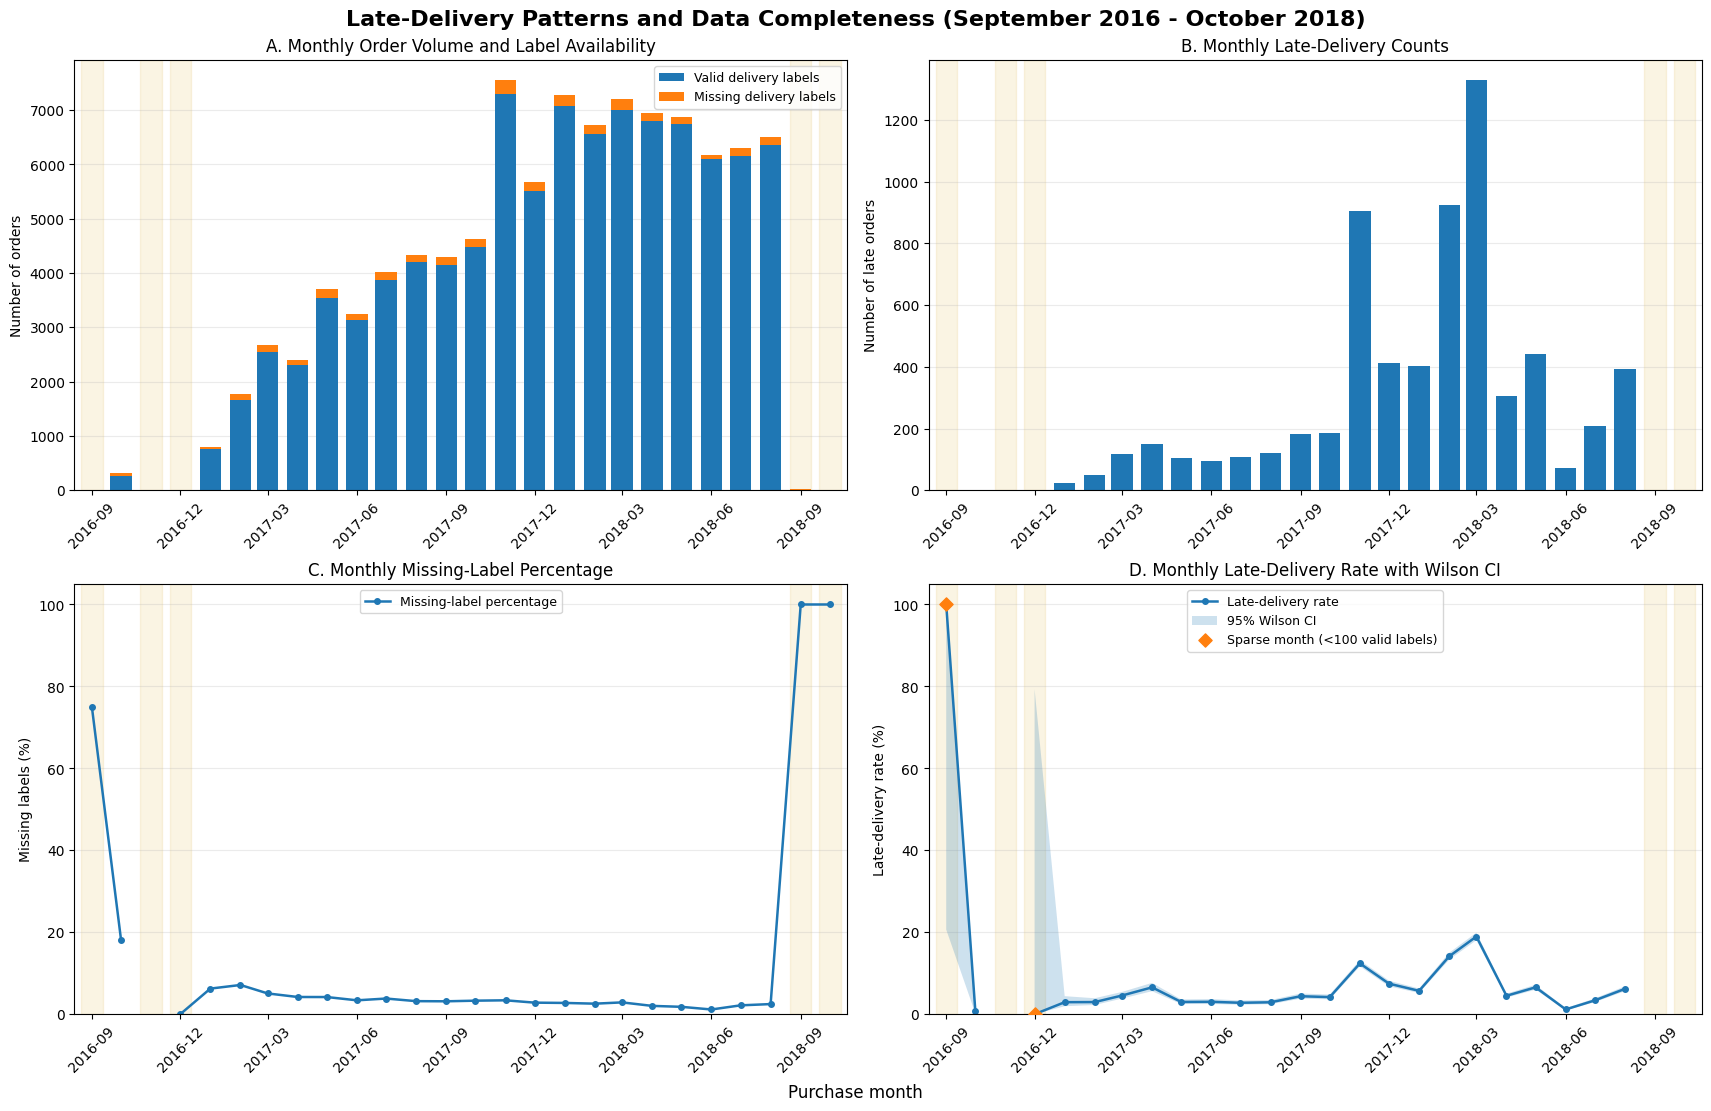


Figure saved successfully:
C:\Users\LENOVO\OneDrive\Desktop\PTTK\outputs\figures\time_analysis\monthly_late_delivery_overview.png

Section 4 completed successfully.


In [5]:
import matplotlib.dates as mdates


# Use calendar dates so months retain their actual spacing.
month_dates = pd.to_datetime(
    monthly_summary["purchase_month"] + "-01",
    format="%Y-%m-%d"
)

x = mdates.date2num(month_dates.to_numpy())

total_counts = monthly_summary[
    "total_orders"
].to_numpy()

valid_counts = monthly_summary[
    "valid_orders"
].to_numpy()

missing_counts = monthly_summary[
    "missing_target_orders"
].to_numpy()

late_counts = monthly_summary[
    "late_orders"
].to_numpy()

missing_pct = monthly_summary[
    "missing_target_percent"
].to_numpy(dtype=float)

# Convert stored proportions to percentages for plotting.
late_pct = (
    monthly_summary["late_rate"].to_numpy(dtype=float)
    * 100
)

ci_lower_pct = (
    monthly_summary["ci_lower"].to_numpy(dtype=float)
    * 100
)

ci_upper_pct = (
    monthly_summary["ci_upper"].to_numpy(dtype=float)
    * 100
)


# Only sparse months with valid labels have rates to mark.
sparse_mask = valid_counts < 100

sparse_valid_mask = (
    sparse_mask & (valid_counts > 0)
)

print("Sparse months (<100 valid labels):")

print(
    monthly_summary.loc[
        sparse_mask,
        ["purchase_month", "valid_orders"]
    ].to_string(index=False)
)


fig_monthly, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(17, 11),
    sharex=True,
    constrained_layout=True
)

ax1, ax2, ax3, ax4 = axes.flat


# Stack valid and missing labels to show total monthly order volume.
ax1.bar(
    x,
    valid_counts,
    width=22,
    label="Valid delivery labels"
)

ax1.bar(
    x,
    missing_counts,
    width=22,
    bottom=valid_counts,
    label="Missing delivery labels"
)

ax1.set_title(
    "A. Monthly Order Volume and Label Availability"
)

ax1.set_ylabel("Number of orders")

ax1.legend(fontsize=9)


ax2.bar(
    x,
    late_counts,
    width=22,
    label="Late orders"
)

ax2.set_title(
    "B. Monthly Late-Delivery Counts"
)

ax2.set_ylabel("Number of late orders")


# Undefined percentages remain gaps in the line.
ax3.plot(
    x,
    missing_pct,
    marker="o",
    markersize=4,
    linewidth=1.8,
    label="Missing-label percentage"
)

ax3.set_title(
    "C. Monthly Missing-Label Percentage"
)

ax3.set_ylabel("Missing labels (%)")

ax3.set_ylim(0, 105)

ax3.legend(fontsize=9)


# Show monthly rates with their Wilson confidence intervals.
ax4.plot(
    x,
    late_pct,
    marker="o",
    markersize=4,
    linewidth=1.8,
    label="Late-delivery rate"
)

ax4.fill_between(
    x,
    ci_lower_pct,
    ci_upper_pct,
    alpha=0.22,
    label="95% Wilson CI"
)

ax4.scatter(
    x[sparse_valid_mask],
    late_pct[sparse_valid_mask],
    marker="D",
    s=45,
    zorder=5,
    label="Sparse month (<100 valid labels)"
)

ax4.set_title(
    "D. Monthly Late-Delivery Rate with Wilson CI"
)

ax4.set_ylabel("Late-delivery rate (%)")

ax4.set_ylim(0, 105)

ax4.legend(fontsize=9)


# Shade all sparse months, including those without valid labels.
for ax_index, ax in enumerate(axes.flat):

    for sparse_index, sparse_x in enumerate(
        x[sparse_mask]
    ):

        ax.axvspan(
            sparse_x - 11,
            sparse_x + 11,
            color="goldenrod",
            alpha=0.12,
            zorder=0
        )

    # Apply the same calendar ticks and formatting to each panel.
    ax.xaxis_date()

    ax.xaxis.set_major_locator(
        mdates.MonthLocator(interval=3)
    )

    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%Y-%m")
    )

    ax.set_xlim(
        x.min() - 18,
        x.max() + 18
    )

    ax.set_ylim(
        bottom=0
    )

    ax.grid(
        axis="y",
        alpha=0.25
    )

    ax.set_axisbelow(True)

    ax.tick_params(
        axis="x",
        labelbottom=True,
        rotation=45
    )


fig_monthly.suptitle(
    "Late-Delivery Patterns and Data Completeness "
    "(September 2016 - October 2018)",
    fontsize=16,
    fontweight="bold"
)

fig_monthly.supxlabel(
    "Purchase month"
)


# Save the combined figure to the project output folder.
figures_dir = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "time_analysis"
)

figures_dir.mkdir(
    parents=True,
    exist_ok=True
)

figure_path = (
    figures_dir
    / "monthly_late_delivery_overview.png"
)

fig_monthly.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


assert figure_path.exists()

assert figure_path.stat().st_size > 0

print("\nFigure saved successfully:")
print(figure_path)

print("\nSection 4 completed successfully.")

## 5. Compare with Delivery EDA

Reconcile monthly valid counts, late counts, rates, grouping, and missing-label rules with the existing EDA. Investigate differences rather than adjusting values to force agreement.


In [6]:
# Prepare a comparison table for months with at least 100 valid labels.
eda03_comparison = monthly_summary.loc[
    monthly_summary["valid_orders"] >= 100,
    [
        "purchase_month",
        "valid_orders",
        "late_orders",
        "late_rate"
    ]
].copy()

# Report percentages rounded to two decimal places.
eda03_comparison["late_rate_pct"] = (
    eda03_comparison["late_rate"] * 100
).round(2)

print("EDA03 COMPARISON TABLE")
print("-" * 60)

print(
    eda03_comparison[
        [
            "purchase_month",
            "valid_orders",
            "late_orders",
            "late_rate_pct"
        ]
    ].to_string(index=False)
)

print("\nHIGHEST LATE-DELIVERY RATE")

print(
    eda03_comparison.nlargest(
        3, "late_rate"
    ).to_string(index=False)
)

print("\nLOWEST LATE-DELIVERY RATE")

print(
    eda03_comparison.nsmallest(
        3, "late_rate"
    ).to_string(index=False)
)

print("\nMonths included:", len(eda03_comparison))
print("Section 5 comparison table prepared.")

EDA03 COMPARISON TABLE
------------------------------------------------------------
purchase_month  valid_orders  late_orders  late_rate_pct
       2016-10           265            2           0.75
       2017-01           750           22           2.93
       2017-02          1653           49           2.96
       2017-03          2546          116           4.56
       2017-04          2303          151           6.56
       2017-05          3545          106           2.99
       2017-06          3135           95           3.03
       2017-07          3872          108           2.79
       2017-08          4193          122           2.91
       2017-09          4150          182           4.39
       2017-10          4478          187           4.18
       2017-11          7288          904          12.40
       2017-12          5513          411           7.46
       2018-01          7069          403           5.70
       2018-02          6555          926          14.13
    

In [7]:
# Reference values transcribed from docs/eda/late_delivery_findings.md.
# Each row contains month, valid orders, late orders, and reported rate (%).
eda03_reference_rows = [
    ("2016-09", 1, 1, 100.00),
    ("2016-10", 265, 2, 0.75),
    ("2016-12", 1, 0, 0.00),
    ("2017-01", 750, 22, 2.93),
    ("2017-02", 1653, 49, 2.96),
    ("2017-03", 2546, 116, 4.56),
    ("2017-04", 2303, 151, 6.56),
    ("2017-05", 3545, 106, 2.99),
    ("2017-06", 3135, 95, 3.03),
    ("2017-07", 3872, 108, 2.79),
    ("2017-08", 4193, 122, 2.91),
    ("2017-09", 4150, 182, 4.39),
    ("2017-10", 4478, 187, 4.18),
    ("2017-11", 7288, 904, 12.40),
    ("2017-12", 5513, 411, 7.46),
    ("2018-01", 7069, 403, 5.70),
    ("2018-02", 6555, 926, 14.13),
    ("2018-03", 7003, 1328, 18.96),
    ("2018-04", 6798, 306, 4.50),
    ("2018-05", 6749, 443, 6.56),
    ("2018-06", 6096, 71, 1.16),
    ("2018-07", 6156, 208, 3.38),
    ("2018-08", 6351, 393, 6.19)
]

eda03_reference = pd.DataFrame(
    eda03_reference_rows,
    columns=[
        "purchase_month",
        "reference_valid",
        "reference_late",
        "reference_rate_pct"
    ]
)


# Compare report values with the independently calculated monthly summary.
comparison = eda03_reference.merge(
    monthly_summary[
        [
            "purchase_month",
            "valid_orders",
            "late_orders",
            "late_rate"
        ]
    ],
    on="purchase_month",
    how="left",
    validate="one_to_one",
    indicator=True
)

comparison["calculated_rate_pct"] = (
    comparison["late_rate"] * 100
)

comparison["valid_match"] = (
    comparison["reference_valid"]
    == comparison["valid_orders"]
)

comparison["late_match"] = (
    comparison["reference_late"]
    == comparison["late_orders"]
)

# Allow 0.0051 percentage points for rates reported to two decimal places.
comparison["rate_match"] = np.isclose(
    comparison["reference_rate_pct"],
    comparison["calculated_rate_pct"],
    atol=0.0051,
    rtol=0
)

comparison["overall_match"] = (
    comparison["valid_match"]
    & comparison["late_match"]
    & comparison["rate_match"]
    & comparison["_merge"].eq("both")
)


print("EDA03 CROSS-ANALYSIS VALIDATION")
print("-" * 55)

print("Reference months:", len(eda03_reference))
print("Matched months:", comparison["overall_match"].sum())
print("Mismatched months:", (~comparison["overall_match"]).sum())

print("\nMISMATCH DETAILS")

mismatches = comparison.loc[
    ~comparison["overall_match"],
    [
        "purchase_month",
        "reference_valid",
        "valid_orders",
        "reference_late",
        "late_orders",
        "reference_rate_pct",
        "calculated_rate_pct"
    ]
]

if mismatches.empty:
    print("No discrepancies detected.")
else:
    print(mismatches.to_string(index=False))

assert len(comparison) == 23
assert comparison["overall_match"].all()

print("\nCross-analysis validation: PASSED")

EDA03 CROSS-ANALYSIS VALIDATION
-------------------------------------------------------
Reference months: 23
Matched months: 23
Mismatched months: 0

MISMATCH DETAILS
No discrepancies detected.

Cross-analysis validation: PASSED


### 5.1. Consistency Results

All 23 months with valid labels match the reference EDA at its reporting precision. Among months with at least 100 labels, March 2018 is highest (18.96%) and October 2016 lowest (0.75%). Within January 2017–August 2018, June 2018 is lowest (1.16%). Sparse and unlabeled months remain in the full table.


## 6. Interpret Results

Read rates alongside sample sizes, missing labels, coverage, and uncertainty. Observed monthly differences are descriptive; no formal month-to-month tests are performed.


In [8]:
# Use pooled labeled-order counts for the overall late-delivery rate.
total_orders = monthly_summary["total_orders"].sum()
valid_orders = monthly_summary["valid_orders"].sum()
late_orders = monthly_summary["late_orders"].sum()
missing_orders = monthly_summary["missing_target_orders"].sum()

overall_late_rate = late_orders / valid_orders * 100

print("OVERALL DATASET STATISTICS")
print("-" * 55)

print(f"Total orders: {total_orders:,}")
print(f"Valid labels: {valid_orders:,}")
print(f"Late orders: {late_orders:,}")
print(f"Missing labels: {missing_orders:,}")
print(f"Overall late-delivery rate: {overall_late_rate:.2f}%")


# Select the five months discussed in the interpretation.
key_months = [
    "2016-10",
    "2017-11",
    "2018-02",
    "2018-03",
    "2018-06"
]

key_findings = monthly_summary.loc[
    monthly_summary["purchase_month"].isin(key_months),
    [
        "purchase_month",
        "valid_orders",
        "late_orders",
        "late_rate",
        "ci_lower",
        "ci_upper"
    ]
].copy()

# Convert rates and interval bounds to percentages for display.
key_findings["late_rate_pct"] = (
    key_findings["late_rate"] * 100
).round(2)

key_findings["ci_lower_pct"] = (
    key_findings["ci_lower"] * 100
).round(2)

key_findings["ci_upper_pct"] = (
    key_findings["ci_upper"] * 100
).round(2)

print("\nKEY MONTHLY FINDINGS")
print("-" * 55)

print(
    key_findings[
        [
            "purchase_month",
            "valid_orders",
            "late_orders",
            "late_rate_pct",
            "ci_lower_pct",
            "ci_upper_pct"
        ]
    ].to_string(index=False)
)


# Find monthly extremes using the minimum sample-size threshold.
eligible_months = monthly_summary.loc[
    monthly_summary["valid_orders"] >= 100
].copy()

highest_month = eligible_months.loc[
    eligible_months["late_rate"].idxmax()
]

lowest_month = eligible_months.loc[
    eligible_months["late_rate"].idxmin()
]

print("\nMONTHLY EXTREMES (AT LEAST 100 VALID LABELS)")
print("-" * 55)

print(
    "Highest:",
    highest_month["purchase_month"],
    f"({highest_month['late_rate'] * 100:.2f}%)"
)

print(
    "Lowest:",
    lowest_month["purchase_month"],
    f"({lowest_month['late_rate'] * 100:.2f}%)"
)


# Check the counts and months used in the interpretation.
assert total_orders == 99441
assert valid_orders == 96470
assert late_orders == 6534
assert missing_orders == 2971

assert len(eligible_months) == 21

assert highest_month["purchase_month"] == "2018-03"
assert lowest_month["purchase_month"] == "2016-10"

assert len(key_findings) == 5

print("\nStatistical evidence verification: PASSED")

OVERALL DATASET STATISTICS
-------------------------------------------------------
Total orders: 99,441
Valid labels: 96,470
Late orders: 6,534
Missing labels: 2,971
Overall late-delivery rate: 6.77%

KEY MONTHLY FINDINGS
-------------------------------------------------------
purchase_month  valid_orders  late_orders  late_rate_pct  ci_lower_pct  ci_upper_pct
       2016-10           265            2           0.75          0.21          2.71
       2017-11          7288          904          12.40         11.67         13.18
       2018-02          6555          926          14.13         13.30         14.99
       2018-03          7003         1328          18.96         18.06         19.90
       2018-06          6096           71           1.16          0.92          1.47

MONTHLY EXTREMES (AT LEAST 100 VALID LABELS)
-------------------------------------------------------
Highest: 2018-03 (18.96%)
Lowest: 2016-10 (0.75%)

Statistical evidence verification: PASSED


### Findings and Limits

- Overall late rate: 6.77% of 96,470 valid labels.
- March 2018: 18.96% (1,328/7,003), Wilson 95% CI about [18.06%, 19.90%].
- June 2018: 1.16% (71/6,096), CI about [0.92%, 1.47%].
- October 2016 has only 265 valid labels; interpret its 0.75% rate cautiously.
- November 2016 has no orders. September and October 2018 have no valid labels, so their rates are undefined.

Wilson intervals assume a binomial model and do not correct shared seller/time effects, missing-label bias, or nonrepresentative sampling. Monthly variation does not prove recurring seasonality, causality, or predictive value.


## 7. Export and Verify

Save `outputs/tables/eda/time_analysis/monthly_late_delivery_summary.csv` and `outputs/figures/time_analysis/monthly_late_delivery_overview.png`. Verify all 26 months, required columns, reconciled counts, 0–1 rates, and preserved missing intervals. Reload the CSV to check consistency; leave the source data unchanged.


In [9]:
tables_dir = PROJECT_ROOT / 'outputs/tables/eda/time_analysis'
figures_dir = PROJECT_ROOT / "outputs" / "figures" / "time_analysis"

tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)


# Keep the ten columns required by TASK 06.
export_columns = [
    "purchase_month",
    "total_orders",
    "valid_orders",
    "late_orders",
    "missing_target_orders",
    "missing_target_percent",
    "late_rate",
    "ci_lower",
    "ci_upper",
    "coverage_note"
]

export_table = monthly_summary[export_columns].copy()


# Check the output structure and complete calendar sequence.
assert len(export_table) == 26
assert export_table.columns.tolist() == export_columns
assert export_table["purchase_month"].is_unique

expected_months = pd.period_range(
    "2016-09",
    "2018-10",
    freq="M"
).strftime("%Y-%m").tolist()

assert export_table["purchase_month"].tolist() == expected_months


# Reconcile overall totals and monthly count relationships.
assert export_table["total_orders"].sum() == 99441
assert export_table["valid_orders"].sum() == 96470
assert export_table["late_orders"].sum() == 6534
assert export_table["missing_target_orders"].sum() == 2971

assert (
    export_table["valid_orders"]
    + export_table["missing_target_orders"]
    == export_table["total_orders"]
).all()

assert (
    export_table["late_orders"]
    <= export_table["valid_orders"]
).all()


has_valid_labels = export_table["valid_orders"] > 0
no_valid_labels = ~has_valid_labels

rate_columns = [
    "late_rate",
    "ci_lower",
    "ci_upper"
]

# Months with valid labels must have rates and intervals on the 0–1 scale.
assert (
    export_table.loc[
        has_valid_labels, rate_columns
    ].notna().all().all()
)

assert (
    export_table.loc[
        has_valid_labels, rate_columns
    ].ge(0).all().all()
)

assert (
    export_table.loc[
        has_valid_labels, rate_columns
    ].le(1).all().all()
)

assert (
    export_table.loc[has_valid_labels, "ci_lower"]
    <= export_table.loc[has_valid_labels, "late_rate"]
).all()

assert (
    export_table.loc[has_valid_labels, "late_rate"]
    <= export_table.loc[has_valid_labels, "ci_upper"]
).all()

# Months without valid labels retain missing rates and intervals.
assert (
    export_table.loc[
        no_valid_labels, rate_columns
    ].isna().all().all()
)

# The missing-label percentage is undefined when no orders are recorded.
no_orders = export_table["total_orders"] == 0

assert (
    export_table.loc[
        no_orders, "missing_target_percent"
    ].isna().all()
)


# Export missing values as empty CSV fields.
summary_path = (
    tables_dir
    / "monthly_late_delivery_summary.csv"
)

export_table.to_csv(
    summary_path,
    index=False,
    encoding="utf-8-sig",
    na_rep=""
)

print("EXPORT COMPLETED")
print("-" * 60)

print("CSV file:", summary_path)
print("Rows:", len(export_table))
print("Columns:", len(export_table.columns))


# Reload the CSV to check that export preserved the calculated results.
reloaded_table = pd.read_csv(
    summary_path,
    dtype={"purchase_month": "string"},
    encoding="utf-8-sig"
)

assert len(reloaded_table) == len(export_table)

assert reloaded_table.columns.tolist() == export_columns

assert (
    reloaded_table["purchase_month"].tolist()
    == export_table["purchase_month"].tolist()
)

count_columns = [
    "total_orders",
    "valid_orders",
    "late_orders",
    "missing_target_orders"
]

for column in count_columns:
    assert (
        reloaded_table[column].to_numpy()
        == export_table[column].to_numpy()
    ).all()

# Allow small floating-point differences and require matching missing values.
numeric_columns = [
    "missing_target_percent",
    "late_rate",
    "ci_lower",
    "ci_upper"
]

for column in numeric_columns:
    np.testing.assert_allclose(
        reloaded_table[column].to_numpy(dtype=float),
        export_table[column].to_numpy(dtype=float),
        rtol=0,
        atol=1e-12,
        equal_nan=True
    )

assert (
    reloaded_table["coverage_note"].tolist()
    == export_table["coverage_note"].tolist()
)

print("\nCSV RELOAD VALIDATION")
print("Exported data matches the calculated summary.")


# Check that the saved figure is nonempty and has a PNG signature.
figure_path = (
    figures_dir
    / "monthly_late_delivery_overview.png"
)

assert figure_path.exists(), "Visualization file not found."

assert figure_path.stat().st_size > 0, "Visualization is empty."

with open(figure_path, "rb") as image_file:
    png_signature = image_file.read(8)

assert png_signature == b"\x89PNG\r\n\x1a\n"

print("\nFIGURE VALIDATION")
print("Figure exists:", figure_path.exists())
print("PNG signature: VALID")
print(
    "Figure size:",
    f"{figure_path.stat().st_size / 1024:.2f} KB"
)


print("\nFINAL TASK 06 VERIFICATION")
print("-" * 60)

print("Complete calendar months: PASSED")
print("Required output columns: PASSED")
print("Order totals: PASSED")
print("Missing-label treatment: PASSED")
print("Wilson confidence intervals: PASSED")
print("CSV export and reload: PASSED")
print("PNG file verification: PASSED")

print("\nTASK 06 output verification completed successfully.")

EXPORT COMPLETED
------------------------------------------------------------
CSV file: C:\Users\LENOVO\OneDrive\Desktop\PTTK\outputs\tables\eda\time_analysis\monthly_late_delivery_summary.csv
Rows: 26
Columns: 10

CSV RELOAD VALIDATION
Exported data matches the calculated summary.

FIGURE VALIDATION
Figure exists: True
PNG signature: VALID
Figure size: 494.16 KB

FINAL TASK 06 VERIFICATION
------------------------------------------------------------
Complete calendar months: PASSED
Required output columns: PASSED
Order totals: PASSED
Missing-label treatment: PASSED
Wilson confidence intervals: PASSED
CSV export and reload: PASSED
PNG file verification: PASSED

TASK 06 output verification completed successfully.
